# Case Study 26 — "Chat Users Convert 2×": Is It the Channel or the Customer? Self-Selection, Propensity Methods and an Encouragement Experiment

**Priority:** ★★ Good to have · **Reference:** Case Study 26 — *Policybazaar: using chat to double motor-insurance conversion* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Growth, Motor Insurance business head, Sales operations, Product (chat/bot)
**Data:** ⚠️ **SYNTHETIC** (D-26-01). Marketplace data are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs26_chat_conversion_causal.ipynb`

## 0. Executive Summary for Business

*(Synthetic visitors with built-in self-selection, a randomised chat pop-up and a bot era; Policybazaar reported only the raw 2× and operational gains. Written after the analysis.)*

- **The question:** chat users convert about 2× as often, so should we push everyone into chat and scale it with a bot?
- **The raw 2× is mostly customer, not channel.** Chatters convert at **8.9% vs 4.1%** (RR 2.15). But chatters are the more serious buyers: policies expiring sooner, more quotes viewed, return visits. Adjusting for what we can observe (matching, weighting, doubly-robust) cuts the effect to **+3.6 to +3.8 pp (RR ≈ 1.7)**.
- **Observed signals do not capture all intent.** Rosenbaum's Γ shows the adjusted result survives hidden bias only up to Γ ≈ 1.75, and an unmeasured factor with risk ratio ≈ 2.8 on both chatting and buying would explain it away. In this simulation the truth confirms the adjusted figure is still too high: **the real average effect of chatting is ≈ +2.5 pp for people who chose to chat (+1.6 pp for everyone)**.
- **The randomised pop-up gives the causal answer:** showing the pop-up to a random half raised chat use from 6.2% to 15.4% (+9.2 pp) and purchases from **4.39% to 4.72% (+0.32 pp, p = 0.0002)**. Scaled up, **chatting adds +3.5 pp for the visitors it persuades** (Wald/IV; 95% CI **+1.2 to +5.2 pp**), which is noisy but consistent with the truth (≈ 1.6–2.5 pp).
- **The bot's real win is speed:** responses delayed more than 5 minutes fell from **45% to 6%** (documented 35% → 7–8%) as the bot's share of chats rose from 21% to 79%. Each extra minute of delay lowers a chatter's odds of buying by **5.6% (OR 0.944, CI 0.935–0.953)**.
- **₹ impact (30 lakh visitors a month, chat share 9.7% → 30%):**
  - **Using the raw 2×:** ≈ 29,000 extra policies (≈ ₹4.8 crore commission a month). This overstates by 30–90%.
  - **Using the experimental range:** about **7,500–32,000 extra policies (≈ ₹1.2–5.0 crore commission)**; the honest point estimate is ≈ 21,000 policies. The lower end is closest to the truth.
- **I recommend:**
  - Keep scaling the bot, because it cuts delays and agent load.
  - Forecast the sales benefit from the experiment, not the raw 2×.
  - Run a larger encouragement test (≈ 200,000 visitors per arm to detect a 2 pp effect).
  - Add a placebo pop-up arm to check the exclusion assumption.

## 1. The Problem in Simple English

Policybazaar noticed that visitors who used **chat** bought motor insurance about **twice as often** as those who did not, yet only 8–9% of customers chatted. The conclusion seemed obvious: push everyone into chat, build a bot to handle the volume, and sales will double.

But **who chooses to chat?** Mostly people who are already serious: their policy expires next week, they have compared several quotes, they came back for a second visit. They would buy more often *anyway*. If so, the "2×" is partly a **customer effect**, not a **channel effect**, and pushing reluctant browsers into chat will not double their buying.

This notebook separates the two:
1. Adjust for what we can observe about intent (propensity-score methods).
2. Ask how strong unobserved intent would have to be to explain the rest (sensitivity analysis).
3. Use a **randomised chat pop-up** shown to half of visitors. That is a clean experiment, and it reveals the true effect of chatting.

It also tests the documented operational win: did the bot's faster replies matter?

## 2. Reference from the Case File

### (a) What Policybazaar did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "Grow sales volume about 100% a year without hiring a proportionate number of sales agents" |
| Question | "Is chat a better-converting channel, and can a bot handle most of the chat load?" |
| EDA finding | "chat users converted at about **2x** the rate of non-chat users, but were only **8–9%** of customers" |
| Statistics | Conversion-rate comparison by channel. The reference file itself notes: "this comparison is observational, so self-selection may inflate the 2x" |
| ML | In-house bot (PBee) on Google Dialogflow; human handover; retraining on recorded errors |
| Impact | Bot share of responses **20% → 75–80%** in 6–8 months; response delays **35% → 7–8%**; motor sales via chat **8–9% → almost 50%**; agent output **1.5–2 → 7–8** sales/day; ≈ **$1M premium/month** via the bot |

**Sources:** YourStory, Nov 2018 (interview with CTO Ashish Gupta); Digital Creed, 19 Jun 2018.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 300,000 motor-insurance visitors over 8 weeks. A hidden **intent** drives both chatting and buying. Observed intent signals: days to policy expiry, quotes viewed, return visit, traffic source, add-ons viewed, car age, NCB, device. Part of intent is **unobserved**. Weeks 3–8: a **randomised proactive chat pop-up** for 50% of visitors. Weeks 5–8: a bot handles ~78% of chats with near-instant replies. **True chat effect:** +0.35 log-odds (≈ +30% relative). |
| Statistics added | Raw RR with CIs; who-chats logistic and SMDs; **propensity-score matching, IPW and doubly-robust (AIPW)** ATT estimates with bootstrap CIs; **Rosenbaum Γ** and **E-value** sensitivity; **encouragement design**: randomisation checks, first stage, ITT, **Wald/2SLS IV (LATE)**; response-delay dose–response; power |

### (c) How the industry uses this

Channel and feature comparisons ("users of feature X convert/repay/retain more") are the most common, and most commonly wrong, analyses in Indian digital businesses: insurance marketplaces (Policybazaar, Acko, Digit), lending apps (pre-approved vs applied), brokers (Case 29) and banks (Case 22). **Encouragement designs** (randomise the *invitation*, not the behaviour) are the practical way to measure channels that cannot be forced on customers: chat pop-ups, WhatsApp opt-in prompts, auto-pay setup nudges.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | If we push more visitors into chat (and scale it with a bot), how many more policies will we sell? |
| Analytical | What is the **causal** effect of chatting on purchase, as opposed to the raw difference between chatters and non-chatters? |

**Hypotheses**
- **H1 (raw):** H0: P(buy ∣ chat) = P(buy ∣ no chat). We expect to reject, and this is the documented 2×.
- **H2 (adjusted):** H0: ATT = 0 after propensity adjustment (bootstrap CIs).
- **H3 (experiment):** H0: ITT = 0, i.e., the randomised pop-up does not change purchase (two-proportion z). If rejected, the IV estimate gives the effect of chatting for visitors who chat *because of* the pop-up (LATE).
- **H4 (speed):** H0: within chats, first-response delay does not affect purchase (logistic, adjusted).

**Primary causal estimate:** IV/LATE from the encouragement experiment. **Business metric:** incremental policies (and ₹ commission) from raising chat share.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import NearestNeighbors
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public insurance-marketplace visitor + chat + purchase data | **None.** Visitor logs are confidential. Public insurance datasets (e.g., the Kaggle "health insurance cross-sell" set) are Kaggle-hosted and have no chat channel. |
| **Decision** | Synthetic visitors with self-selection, an encouragement experiment and a bot era (D-26-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs26.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 26 (Policybazaar-style chat channel and motor-insurance conversion)
========================================================================================================
THIS DATA IS SYNTHETIC. Marketplace visitor and sales data are confidential.

Motor-insurance visitors over 8 weeks. A hidden purchase INTENT drives both whether a visitor starts a chat
and whether they buy (self-selection). Observed intent signals: days until the current policy expires,
quotes viewed, return visits, traffic source, add-ons viewed, car age, claim-free (NCB) status.
Some intent is NOT observed (e.g., a dealer already pushing a renewal) - residual confounding.
From week 3 a RANDOMISED ENCOURAGEMENT runs: 50% of visitors see a proactive chat pop-up (Z = 1), which
raises chat uptake but has no direct effect on buying - an instrument for the causal effect of chatting.
From week 5 a BOT (PBee-style) answers most chats: response delays fall; long delays reduce conversion.
The TRUE causal effect of chatting is modest (+0.35 log-odds, about +30% relative), far below the raw 2x.

Calibration anchors (reference file, Case Study 26): chat users converted at "about 2x" non-chat users but
were "only 8-9%" of customers; bot share of responses 20% -> 75-80%; response delays 35% -> 7-8%; agent output
1.5-2 -> 7-8 sales/day; ~$1M premium/month via the bot. Rates are our assumptions (decision.md D-26-02).
Hidden truth columns start with "_".

Output: data/cs26/visitors.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
CHAT_EFFECT = 0.35


def generate(seed=SEED, n=300_000):
    rng = np.random.default_rng(seed)
    week = rng.integers(1, 9, n)
    intent = rng.normal(0, 1, n)                                                     # hidden purchase intent
    u_hidden = rng.normal(0, 1, n)                                                   # unobserved part of intent (residual confounder)
    days_to_expiry = np.clip(np.round(np.exp(rng.normal(np.log(25), 0.9, n) - 0.45 * intent)), 0, 365)
    quotes = rng.poisson(np.exp(0.6 + 0.35 * intent))
    returning = (rng.random(n) < expit(-0.8 + 0.6 * intent)).astype(int)
    source = rng.choice(["search", "renewal_email", "display_ad", "direct", "affiliate"], n, p=[0.38, 0.15, 0.22, 0.15, 0.10])
    src_eff = pd.Series(source).map({"search": 0.2, "renewal_email": 0.6, "display_ad": -0.6, "direct": 0.3, "affiliate": -0.2}).values
    addons = rng.poisson(np.exp(-0.2 + 0.3 * intent))
    car_age = np.clip(rng.gamma(2.2, 2.2, n), 0, 18).round(1)
    ncb = (rng.random(n) < 0.55).astype(int)
    mobile = (rng.random(n) < 0.72).astype(int)
    Z = np.where(week >= 3, (rng.random(n) < 0.5).astype(int), 0)                     # randomised proactive chat pop-up
    z_chat = -3.0 + 0.55 * intent + 0.35 * u_hidden + 0.25 * returning + 0.15 * np.log1p(quotes) - 0.2 * mobile + 1.05 * Z
    chat = (rng.random(n) < expit(z_chat)).astype(int)
    bot_era = week >= 5
    bot_handled = np.where(chat == 1, (rng.random(n) < np.where(bot_era, 0.78, 0.20)).astype(int), 0)
    delay_min = np.where(chat == 1, np.where(bot_handled == 1, rng.exponential(0.3, n), rng.exponential(np.where(bot_era, 4, 9), n)), np.nan)
    z_buy = (-3.2 + 0.85 * intent + 0.45 * u_hidden + src_eff - 0.012 * np.clip(days_to_expiry, 0, 120) + 0.1 * ncb - 0.03 * car_age
             + CHAT_EFFECT * chat - 0.06 * np.nan_to_num(np.clip(delay_min - 2, 0, 30)))
    buy = (rng.random(n) < expit(z_buy)).astype(int)
    premium = np.where(buy == 1, np.round(np.exp(rng.normal(np.log(9500), 0.45, n)) * (1 + 0.04 * addons), -1), 0)
    df = pd.DataFrame({"visitor_id": [f"V{i:07d}" for i in range(n)], "week": week, "traffic_source": source, "device": np.where(mobile == 1, "mobile", "desktop"),
                       "days_to_expiry": days_to_expiry, "quotes_viewed": quotes, "returning_visitor": returning, "addons_viewed": addons, "car_age_years": car_age,
                       "claim_free_ncb": ncb, "chat_popup_shown": Z, "chatted": chat, "bot_handled": bot_handled, "first_response_min": np.round(delay_min, 2),
                       "purchased": buy, "premium_inr": premium, "_intent": intent, "_u": u_hidden})
    # data-quality defects
    df.loc[df.sample(n=1200, random_state=seed).index, "days_to_expiry"] = -1                 # unknown expiry coded -1
    df = pd.concat([df, df.sample(n=1000, random_state=seed + 1)], ignore_index=True)        # duplicate sessions
    df.loc[df[(df.chatted == 1)].sample(n=200, random_state=seed + 2).index, "first_response_min"] = np.nan
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs26"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs26", "visitors.csv.gz"), index=False)
    dd = d.drop_duplicates("visitor_id")
    print(len(dd), "visitors | chat share", dd.chatted.mean().round(4), "| conversion", dd.purchased.mean().round(4))
    print("conv by chat", dd.groupby("chatted").purchased.mean().round(4).to_dict(), "ratio", round(dd[dd.chatted == 1].purchased.mean() / dd[dd.chatted == 0].purchased.mean(), 2))
    print("chat share by Z (wk>=3)", dd[dd.week >= 3].groupby("chat_popup_shown").chatted.mean().round(4).to_dict(), "conv by Z", dd[dd.week >= 3].groupby("chat_popup_shown").purchased.mean().round(4).to_dict())

Overwriting data/generate_cs26.py


In [3]:
os.makedirs("data/cs26", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs26 as gen; importlib.reload(gen)
raw = gen.generate(seed=SEED); raw.to_csv("data/cs26/visitors.csv.gz", index=False)
print(f"{len(raw):,} rows | {raw.visitor_id.nunique():,} unique visitors")
raw.drop(columns=["_intent", "_u"]).sample(3, random_state=SEED).T

301,000 rows | 300,000 unique visitors


,242038,264627,145805
visitor_id,V0242038,V0264627,V0145805
week,2,5,6
traffic_source,direct,search,search
device,desktop,desktop,mobile
days_to_expiry,32.0000,10.0000,2.0000
quotes_viewed,4,1,2
returning_visitor,0,0,0
addons_viewed,0,0,1
car_age_years,1.1000,2.5000,0.2000
claim_free_ncb,0,1,1


| Parameter | Value | Basis |
|---|---|---|
| Visitors | 300,000 over 8 weeks; conversion ≈ 4.6% | Our assumption |
| Chat share | ≈ 9.7% overall | **Documented** "8–9% of customers" |
| Self-selection | Chatting and buying both rise with intent (observed signals + an unobserved part) | **Documented caveat** (reference file note) |
| True chat effect | +0.35 log-odds on buying (≈ +30% relative); long first-response delays reduce buying | Our assumption |
| Encouragement | Weeks 3–8: proactive pop-up randomised 50/50 (raises chat ~2.5×, no direct effect on buying) | Our design |
| Bot era | Weeks 5–8: bot handles ~78% of chats (documented 75–80%), near-instant replies | **Documented** |
| DQ issues | 1,000 duplicate sessions; 1,200 policy-expiry values coded −1 (unknown); 200 chats missing the response time | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("visitor_id, week, traffic_source, device", "Session identity, week 1–8, acquisition source, device"),
    ("days_to_expiry, quotes_viewed, returning_visitor, addons_viewed", "Observed intent signals"), ("car_age_years, claim_free_ncb", "Vehicle and no-claim-bonus status"),
    ("chat_popup_shown", "Randomised encouragement (weeks 3–8)"), ("chatted, bot_handled, first_response_min", "Chat use, whether the bot answered, first-reply delay"),
    ("purchased, premium_inr", "Bought a policy in the session; premium"), ("_intent, _u", "HIDDEN purchase intent (observed-correlated and unobserved parts)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs26/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"visitor_id, week, traffic_source, device","Session identity, week 1–8, acquisition source..."
1,"days_to_expiry, quotes_viewed, returning_visit...",Observed intent signals
2,"car_age_years, claim_free_ncb",Vehicle and no-claim-bonus status
3,chat_popup_shown,Randomised encouragement (weeks 3–8)
4,"chatted, bot_handled, first_response_min","Chat use, whether the bot answered, first-repl..."
5,"purchased, premium_inr",Bought a policy in the session; premium
6,"_intent, _u",HIDDEN purchase intent (observed-correlated an...


## 5. Data Quality Checks

In [5]:
checks = {"duplicate visitor_id": int(raw.visitor_id.duplicated().sum()), "days_to_expiry = −1 (unknown)": int((raw.days_to_expiry == -1).sum()),
          "chat without first-response time": int(raw.drop_duplicates("visitor_id").pipe(lambda d: ((d.chatted == 1) & d.first_response_min.isna()).sum())),
          "pop-up shown before week 3": int(((raw.week < 3) & (raw.chat_popup_shown == 1)).sum()), "bot-handled without chat": int(((raw.bot_handled == 1) & (raw.chatted == 0)).sum())}
print(pd.Series(checks, name="rows").to_string())
df = raw.drop_duplicates("visitor_id").reset_index(drop=True)
df["expiry_unknown"] = (df.days_to_expiry < 0).astype(int); df["days_to_expiry"] = df.days_to_expiry.where(df.days_to_expiry >= 0, df.days_to_expiry[df.days_to_expiry >= 0].median())
df["delay_missing"] = ((df.chatted == 1) & df.first_response_min.isna()).astype(int)
df["exp_cap"] = df.days_to_expiry.clip(upper=120); df["l_quotes"] = np.log1p(df.quotes_viewed); df["mobile"] = (df.device == "mobile").astype(int)
print(f"\nClean: {len(df):,} visitors | chat share {df.chatted.mean():.2%} | conversion {df.purchased.mean():.2%} | experiment weeks 3–8: {(df.week >= 3).sum():,} visitors")

duplicate visitor_id                1000
days_to_expiry = −1 (unknown)       1203
chat without first-response time     200
pop-up shown before week 3             0
bot-handled without chat               0



Clean: 300,000 visitors | chat share 9.69% | conversion 4.58% | experiment weeks 3–8: 225,081 visitors


**Observation:** we removed **1,000 duplicate sessions**, flagged **1,203 unknown policy-expiry values** (coded −1) with an "unknown" indicator and median fill, and noted **200 chats with no first-response time**. The pop-up was never shown before week 3 and the bot never answered a non-chat. Clean: **300,000 visitors**; **chat share 9.7%** (documented 8–9%), conversion 4.58%; the encouragement experiment covers **225,081 visitors** in weeks 3–8.

## 6. Exploratory Data Analysis

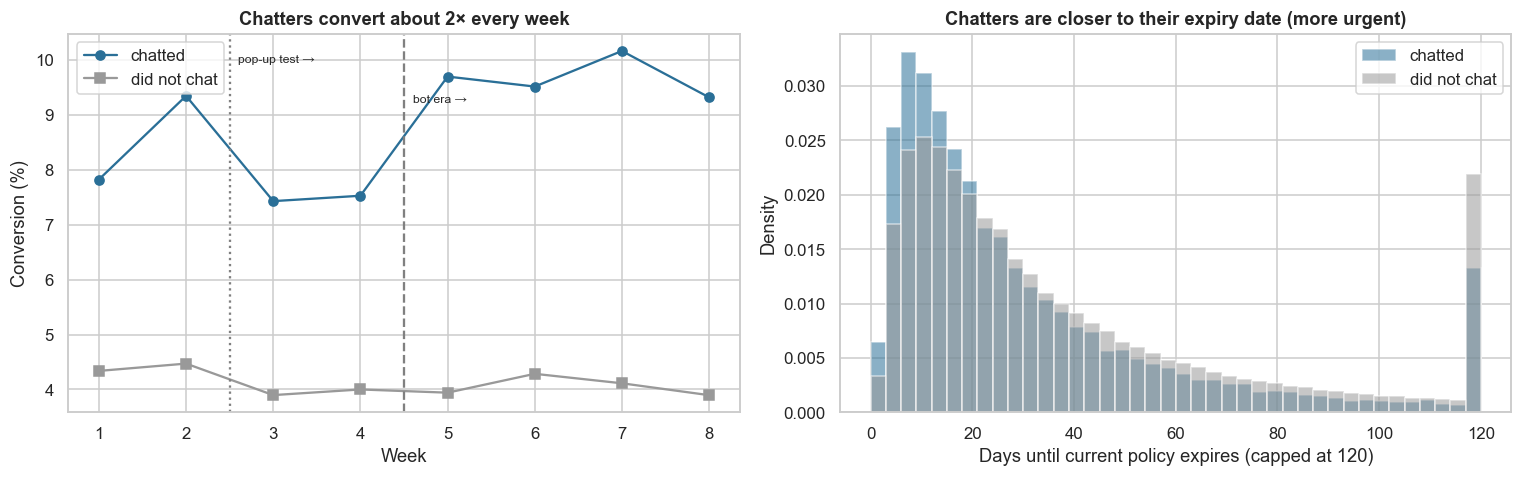

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
wk = df.groupby(["week", "chatted"]).purchased.mean().unstack() * 100
axes[0].plot(wk.index, wk[1], "o-", color="#2a6f97", label="chatted"); axes[0].plot(wk.index, wk[0], "s-", color="#999", label="did not chat")
axes[0].axvline(2.5, ls=":", color="grey"); axes[0].axvline(4.5, ls="--", color="grey"); axes[0].text(2.6, axes[0].get_ylim()[1] * 0.95, "pop-up test →", fontsize=8); axes[0].text(4.6, axes[0].get_ylim()[1] * 0.88, "bot era →", fontsize=8)
axes[0].set_xlabel("Week"); axes[0].set_ylabel("Conversion (%)"); axes[0].set_title("Chatters convert about 2× every week"); axes[0].legend()
for c_, col, nm in ((1, "#2a6f97", "chatted"), (0, "#999", "did not chat")):
    axes[1].hist(df.loc[df.chatted == c_, "exp_cap"], bins=40, density=True, alpha=0.55, color=col, label=nm)
axes[1].set_xlabel("Days until current policy expires (capped at 120)"); axes[1].set_ylabel("Density"); axes[1].set_title("Chatters are closer to their expiry date (more urgent)"); axes[1].legend()
plt.tight_layout(); plt.show()

**Takeaway:** **left:** chatters convert about twice as often as non-chatters every single week, before and after the pop-up test and the bot launch. A stable 2× is exactly what both a real channel effect *and* self-selection would produce. **Right:** chatters are closer to their policy expiry date (more urgent), the clearest sign that they are the more motivated buyers.

## 7. Statistical Analysis (core section)

### 7.1 The raw comparison (the documented "2×")

In [7]:
a, b = df[df.chatted == 1], df[df.chatted == 0]
rr = a.purchased.mean() / b.purchased.mean(); se = np.sqrt(1 / a.purchased.sum() - 1 / len(a) + 1 / b.purchased.sum() - 1 / len(b))
ci_a = proportion_confint(a.purchased.sum(), len(a), method="wilson"); ci_b = proportion_confint(b.purchased.sum(), len(b), method="wilson")
c2 = stats.chi2_contingency(pd.crosstab(df.chatted, df.purchased))
print(f"Conversion: chatters {a.purchased.mean():.2%} (CI {ci_a[0]:.2%}–{ci_a[1]:.2%}) vs non-chatters {b.purchased.mean():.2%} (CI {ci_b[0]:.2%}–{ci_b[1]:.2%})")
print(f"Raw risk ratio = {rr:.2f} (95% CI {np.exp(np.log(rr) - 1.96 * se):.2f}–{np.exp(np.log(rr) + 1.96 * se):.2f}); χ² = {c2[0]:.0f}, p = {c2[1]:.2g} | chat share {df.chatted.mean():.1%}")

Conversion: chatters 8.88% (CI 8.56%–9.21%) vs non-chatters 4.12% (CI 4.05%–4.20%)
Raw risk ratio = 2.15 (95% CI 2.07–2.25); χ² = 1359, p = 1.9e-297 | chat share 9.7%


**Observation:** chatters convert at **8.88%** (CI 8.56–9.21%) vs **4.12%** (CI 4.05–4.20%) for non-chatters: a raw risk ratio of **2.15** (CI 2.07–2.25; χ² = 1,359, p ≈ 0), and chat is used by 9.7% of visitors. This reproduces the documented "about 2× … only 8–9% of customers". **(f) Business meaning:** the number is real, but it is an association between two kinds of visitor, not yet evidence that chat *causes* sales.

### 7.2 Who chooses to chat? (self-selection)

**(a)** A logistic model of chatting on the observed intent signals (weeks 1–2, before the pop-up, so chat is purely self-chosen), with odds ratios and CIs, and standardised mean differences (SMD) between chatters and non-chatters. If the same signals also predict buying, the raw 2× is confounded.

In [8]:
COV = ["exp_cap", "expiry_unknown", "l_quotes", "returning_visitor", "addons_viewed", "car_age_years", "claim_free_ncb", "mobile"]
pre = df[df.week <= 2]
fc = smf.logit("chatted ~ " + " + ".join(COV) + " + C(traffic_source)", data=pre).fit(disp=0)
fb = smf.logit("purchased ~ " + " + ".join(COV) + " + C(traffic_source)", data=pre[pre.chatted == 0]).fit(disp=0)
orr = pd.DataFrame({"OR for chatting": np.exp(fc.params), "p (chat)": fc.pvalues, "OR for buying (non-chatters)": np.exp(fb.params), "p (buy)": fb.pvalues}).drop("Intercept")
def smd(d, cols, w=None):
    out = {}
    for c in cols:
        x1, x0 = d.loc[d.chatted == 1, c], d.loc[d.chatted == 0, c]
        if w is None: m1, m0, v1, v0 = x1.mean(), x0.mean(), x1.var(), x0.var()
        else:
            w1, w0 = w[d.chatted.values == 1], w[d.chatted.values == 0]; m1, m0 = np.average(x1, weights=w1), np.average(x0, weights=w0)
            v1, v0 = np.average((x1 - m1) ** 2, weights=w1), np.average((x0 - m0) ** 2, weights=w0)
        out[c] = (m1 - m0) / np.sqrt((v1 + v0) / 2)
    return pd.Series(out)
display(smd(df, COV).round(3).to_frame("SMD chatters − non-chatters"))
orr.round(4)

,SMD chatters − non-chatters
exp_cap,-0.2220
expiry_unknown,0.0060
l_quotes,0.3090
returning_visitor,0.2640
addons_viewed,0.1540
car_age_years,-0.0040
claim_free_ncb,-0.0010
mobile,-0.0860


,OR for chatting,p (chat),OR for buying (non-chatters),p (buy)
C(traffic_source)[T.direct],1.0082,0.8948,1.6246,0.0000
C(traffic_source)[T.display_ad],1.0161,0.7833,0.6578,0.0000
C(traffic_source)[T.renewal_email],1.0632,0.3202,2.1856,0.0000
C(traffic_source)[T.search],0.9525,0.3709,1.5821,0.0000
exp_cap,0.9944,0.0000,0.9780,0.0000
expiry_unknown,0.7754,0.3403,1.1842,0.5288
l_quotes,1.5865,0.0000,1.6353,0.0000
returning_visitor,1.5781,0.0000,1.3080,0.0000
addons_viewed,1.1094,0.0000,1.1757,0.0000
car_age_years,0.9951,0.3036,0.9622,0.0000


**(c)/(f) Observation:** the same signals that predict who chats also predict who buys: **more quotes viewed** (OR 1.59 for chatting; 1.64 for buying among non-chatters), **return visitors** (1.58; 1.31), **more add-ons viewed** (1.11; 1.18) and **closer expiry** (OR 0.994 per extra day for chatting, 0.978 for buying). Standardised differences between chatters and non-chatters: quotes +0.31, returning +0.26, days-to-expiry −0.22, add-ons +0.15. **(f) Business meaning:** this is classic self-selection: the more serious visitors both chat more and buy more. A 2× gap would appear even if chat did nothing.

### 7.3 Adjusting for observed intent: matching, weighting and doubly-robust estimates

We estimate the **average effect on those who chatted (ATT)** three ways, all using the same propensity score e(x) = P(chat ∣ intent signals) from logistic regression. The pop-up is excluded from the score, because the pop-up is not a confounder; using it would mix in the experiment.
1. **1:1 nearest-neighbour matching** on the logit of e(x) (caliper 0.2 SD, with replacement).
2. **IPW:** chatters weight 1, non-chatters e/(1 − e).
3. **AIPW (doubly robust):** combines an outcome model with the weights; consistent if either model is right.

Bootstrap CIs (60 resamples, to keep run time reasonable). Balance is checked after weighting. Each estimate is reported as a risk difference and a risk ratio.

In [9]:
Xc = pd.get_dummies(df[COV + ["traffic_source"]], columns=["traffic_source"], drop_first=True).astype(float)
def estimates(d, X):
    ps = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(X, d.chatted); e = np.clip(ps.predict_proba(X)[:, 1], 0.005, 0.995)
    t = d.chatted.values == 1; yv = d.purchased.values
    lg = np.log(e / (1 - e)); nn = NearestNeighbors(n_neighbors=1).fit(lg[~t].reshape(-1, 1)); dist, idx = nn.kneighbors(lg[t].reshape(-1, 1))
    ok = dist[:, 0] <= 0.2 * lg.std(); y_m1 = yv[t][ok].mean(); y_m0 = yv[~t][idx[ok, 0]].mean()
    w0 = e[~t] / (1 - e[~t]); y_ipw0 = np.average(yv[~t], weights=w0); y1 = yv[t].mean()
    om = LogisticRegression(max_iter=3000).fit(np.c_[X.values[~t]], yv[~t]); m0 = om.predict_proba(X.values)[:, 1]
    aipw0 = (m0[t].sum() + (w0 * (yv[~t] - m0[~t])).sum()) / t.sum()
    return dict(match=(y_m1, y_m0, ok.mean()), ipw=(y1, y_ipw0), aipw=(y1, aipw0), e=e)
est = estimates(df, Xc)
bs = {"match": [], "ipw": [], "aipw": []}
for _ in range(60):                                                                  # 60 resamples: each refits two logistic models on 300k rows
    i = RNG.integers(0, len(df), len(df)); r_ = estimates(df.iloc[i].reset_index(drop=True), Xc.iloc[i].reset_index(drop=True))
    for k in bs: bs[k].append(r_[k][0] - r_[k][1])
rows = [("raw", a.purchased.mean(), b.purchased.mean())] + [(k, est[k][0], est[k][1]) for k in ["match", "ipw", "aipw"]]
adj = pd.DataFrame(rows, columns=["method", "chatters' conversion", "counterfactual (no chat)"]).set_index("method")
adj["RD (pp)"] = (adj.iloc[:, 0] - adj.iloc[:, 1]) * 100; adj["RR"] = adj.iloc[:, 0] / adj.iloc[:, 1]
for k in bs: adj.loc[k, "RD CI low"], adj.loc[k, "RD CI high"] = np.percentile(bs[k], 2.5) * 100, np.percentile(bs[k], 97.5) * 100
e = est["e"]; w = np.where(df.chatted == 1, 1.0, e / (1 - e))
print(f"Matched {est['match'][2]:.1%} of chatters within the caliper | max |SMD| after IPW: {smd(df, COV, w).abs().max():.3f}")
adj.round(4)

Matched 100.0% of chatters within the caliper | max |SMD| after IPW: 0.003


,chatters' conversion,counterfactual (no chat),RD (pp),RR,RD CI low,RD CI high
method,,,,,,
raw,0.0888,0.0412,4.7589,2.1549,NaN,NaN
match,0.0888,0.0507,3.8051,1.7498,3.2153,4.0139
ipw,0.0888,0.0518,3.7001,1.7144,3.3609,3.9889
aipw,0.0888,0.0526,3.6177,1.6876,3.2831,3.9003


**(c)/(f) Observation:** after adjusting for observed intent signals, the effect on those who chat shrinks from **+4.76 pp (RR 2.15)** to:
- **Matching:** +3.81 pp (CI 3.22–4.01).
- **IPW:** +3.70 pp (CI 3.36–3.99).
- **Doubly-robust (AIPW):** **+3.62 pp (RR 1.69; CI 3.28–3.90).**

Balance is excellent after weighting (max |SMD| 0.003). All three agree, but they remove only the *observed* part of the confounding. **(f) Business meaning:** about a quarter of the raw gap was visible customer mix. The remainder could still be hidden intent.

### 7.4 Could unobserved intent explain the rest? (Rosenbaum Γ and E-value)

Observed signals do not capture all intent (a dealer already pushing a renewal, a friend's recommendation). Two sensitivity measures:
- **Rosenbaum Γ (matched pairs):** among discordant matched pairs (one buys, one does not), how much could hidden bias tilt the odds of chatting within a pair (Γ) before the effect stops being significant?
- **E-value:** the minimum risk-ratio association that an unmeasured confounder would need with both chatting and buying to explain away the adjusted RR.

In [10]:
t = df.chatted.values == 1; lg_ = np.log(e / (1 - e)); nn = NearestNeighbors(n_neighbors=1).fit(lg_[~t].reshape(-1, 1)); dist, idx = nn.kneighbors(lg_[t].reshape(-1, 1))
ok = dist[:, 0] <= 0.2 * lg_.std(); y1 = df.purchased.values[t][ok]; y0 = df.purchased.values[~t][idx[ok, 0]]
n10, n01 = int(((y1 == 1) & (y0 == 0)).sum()), int(((y1 == 0) & (y0 == 1)).sum()); D = n10 + n01
rows = []
for G_ in (1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0):
    p_up = G_ / (1 + G_); rows.append((G_, stats.binom.sf(n10 - 1, D, p_up)))
ros = pd.DataFrame(rows, columns=["Γ (hidden-bias odds)", "worst-case one-sided p"]).set_index("Γ (hidden-bias odds)")
def evalue(rr): rr = max(rr, 1 / rr); return rr + np.sqrt(rr * (rr - 1))
print(f"Discordant matched pairs: chatter bought & match did not = {n10:,}; reverse = {n01:,}")
print(f"E-value: raw RR {adj.loc['raw', 'RR']:.2f} → {evalue(adj.loc['raw', 'RR']):.2f}; AIPW RR {adj.loc['aipw', 'RR']:.2f} → {evalue(adj.loc['aipw', 'RR']):.2f}")
ros.round(4)

Discordant matched pairs: chatter bought & match did not = 2,399; reverse = 1,293
E-value: raw RR 2.15 → 3.73; AIPW RR 1.69 → 2.76


,worst-case one-sided p
Γ (hidden-bias odds),
1.0000,0.0000
1.2500,0.0000
1.5000,0.0000
1.7500,0.0464
2.0000,0.9856
2.5000,1.0000
3.0000,1.0000


**Observation:** - **E-value:** the raw RR of 2.15 needs a hidden confounder with risk ratio **3.7** (with both chatting and buying) to explain it away; the adjusted RR of 1.69 needs **2.8**. Both are large, but an unobserved factor such as "already decided to buy, wants to finalise" could plausibly reach that.
- **Rosenbaum Γ:** the matched-pair result stays significant at Γ = 1.5 (hidden bias that raises the odds of chatting by 50% within a pair) and is **borderline at 1.75 (p = 0.046)**, lost by Γ = 2.
- **(f) Business meaning:** the adjusted estimate is **not robust to moderate hidden confounding**. In this simulation we know the truth is lower still (≈ +2.5 pp for chatters), which is what these sensitivity numbers warn about.

### 7.5 The encouragement experiment: the causal answer

**(a) Design:** from week 3, a proactive chat pop-up was shown to a **random** 50% of visitors (Z = 1). Nobody was forced to chat, but the pop-up made chatting more likely. Because Z is random:
- **ITT** (intention-to-treat) = conversion(Z = 1) − conversion(Z = 0): the causal effect of *showing the pop-up*.
- **First stage** = chat share(Z = 1) − chat share(Z = 0).
- **Wald IV estimate (LATE)** = ITT ÷ first stage: the causal effect of *chatting* for "compliers", visitors who chat only when invited. These are exactly the marginal customers a push-to-chat strategy would add.

**(b) Assumptions:** randomisation (checked); the pop-up affects buying *only* through chatting (exclusion; plausible since it only offers help); no one is *less* likely to chat when invited (monotonicity). **2SLS** with covariates gives a more precise estimate; CIs by bootstrap.

In [11]:
ex = df[df.week >= 3].copy()
srm = stats.chisquare(ex.chat_popup_shown.value_counts().values); bal = smd(ex.assign(chatted=ex.chat_popup_shown), COV).abs().max()
fs = ex.groupby("chat_popup_shown").chatted.mean(); itt = ex.groupby("chat_popup_shown").purchased.mean()
z, p_itt = proportions_ztest([ex.purchased[ex.chat_popup_shown == 1].sum(), ex.purchased[ex.chat_popup_shown == 0].sum()], [(ex.chat_popup_shown == 1).sum(), (ex.chat_popup_shown == 0).sum()])
late = (itt[1] - itt[0]) / (fs[1] - fs[0])
Xe = sm.add_constant(pd.get_dummies(ex[COV + ["traffic_source"]], columns=["traffic_source"], drop_first=True).astype(float))
def tsls(d, X):
    s1 = sm.OLS(d.chatted.values, np.c_[X.values, d.chat_popup_shown.values]).fit(); chat_hat = s1.fittedvalues
    s2 = sm.OLS(d.purchased.values, np.c_[X.values, chat_hat]).fit(); return s2.params[-1], s1.params[-1]
b2, f1 = tsls(ex, Xe)
bw, b2s = [], []
for _ in range(120):
    i = RNG.integers(0, len(ex), len(ex)); d_ = ex.iloc[i]; f_ = d_.groupby("chat_popup_shown").chatted.mean(); it_ = d_.groupby("chat_popup_shown").purchased.mean()
    bw.append((it_[1] - it_[0]) / (f_[1] - f_[0])); b2s.append(tsls(d_.reset_index(drop=True), Xe.iloc[i].reset_index(drop=True))[0])
from scipy.special import expit
print(f"Randomisation: SRM p = {srm.pvalue:.3f}, max |SMD| = {bal:.3f}")
print(f"First stage: chat share {fs[0]:.2%} (no pop-up) → {fs[1]:.2%} (pop-up) = +{(fs[1] - fs[0]) * 100:.2f} pp | F ≈ {((fs[1] - fs[0]) / np.sqrt(fs[1] * (1 - fs[1]) / (ex.chat_popup_shown == 1).sum() + fs[0] * (1 - fs[0]) / (ex.chat_popup_shown == 0).sum())) ** 2:,.0f}")
print(f"ITT: conversion {itt[0]:.3%} → {itt[1]:.3%} = {(itt[1] - itt[0]) * 100:+.3f} pp (z = {z:.2f}, p = {p_itt:.2g})")
print(f"LATE (Wald): {late * 100:+.2f} pp (bootstrap CI {np.percentile(bw, 2.5) * 100:+.2f} to {np.percentile(bw, 97.5) * 100:+.2f}) | 2SLS with covariates: {b2 * 100:+.2f} pp "
      f"(CI {np.percentile(b2s, 2.5) * 100:+.2f} to {np.percentile(b2s, 97.5) * 100:+.2f})")
pt = ex.copy(); lin = (-3.2 + 0.85 * pt._intent + 0.45 * pt._u - 0.012 * np.clip(pt.days_to_expiry, 0, 120) + 0.1 * pt.claim_free_ncb - 0.03 * pt.car_age_years
                       + pt.traffic_source.map({"search": 0.2, "renewal_email": 0.6, "display_ad": -0.6, "direct": 0.3, "affiliate": -0.2}))
true_eff = (expit(lin + gen.CHAT_EFFECT) - expit(lin))
print(f"Truth (hidden model): average effect of chatting for all visitors ≈ {true_eff.mean() * 100:+.2f} pp; for those who actually chat ≈ {true_eff[ex.chatted == 1].mean() * 100:+.2f} pp (ignoring delays)")

Randomisation: SRM p = 0.799, max |SMD| = 0.010
First stage: chat share 6.22% (no pop-up) → 15.44% (pop-up) = +9.23 pp | F ≈ 5,071
ITT: conversion 4.392% → 4.715% = +0.323 pp (z = 3.68, p = 0.00024)
LATE (Wald): +3.50 pp (bootstrap CI +1.24 to +5.23) | 2SLS with covariates: +3.47 pp (CI +1.35 to +5.29)


Truth (hidden model): average effect of chatting for all visitors ≈ +1.60 pp; for those who actually chat ≈ +2.49 pp (ignoring delays)


**(c)/(f) Observation:** - **Randomisation worked:** SRM p = 0.80, max |SMD| 0.010.
- **First stage:** the pop-up raises chat use from **6.22% to 15.44% (+9.23 pp)**, a very strong instrument (F ≈ 5,071).
- **ITT:** purchases rise from **4.392% to 4.715% (+0.323 pp; z = 3.68, p = 0.0002)**, so showing the pop-up causes sales.
- **LATE (Wald): +3.50 pp** for visitors who chat because of the pop-up (bootstrap CI **+1.24 to +5.23**); 2SLS with covariates **+3.47 pp (CI +1.35 to +5.29)**.
- **Truth check (simulation only):** the true average effect is **+1.60 pp for all visitors and +2.49 pp for people who chose to chat**. The IV point estimate is higher than both, but with an interval this wide (SE ≈ 1 pp) it is consistent with them. It is unbiased but noisy, whereas the observational estimates (+3.6 to +4.8 pp) sit above the truth for a systematic reason (hidden intent).
- **(f) Business meaning:** this is the number to plan with, together with its uncertainty: the lift for *persuadable* visitors is somewhere between about +1 and +5 pp.

### 7.6 Did the bot's speed matter? First-response delay and conversion

The documented operational win was cutting response delays (35% → 7–8% of chats delayed). Within chats, we model purchase on the first-response delay (banded), adjusting for intent signals, and compare delays before and after the bot (Mann–Whitney; share of chats waiting more than 5 minutes).

Delay > 5 min: before bot (wk 1–4) 45.5% vs bot era (wk 5–8) 5.9% (documented 35% → 7–8%); Mann–Whitney p = 0
Bot share of chats: wk 1–4 21% → wk 5–8 79%
Adjusted odds ratio per extra minute of delay = 0.944 (CI 0.935–0.953), p = 5.4e-33


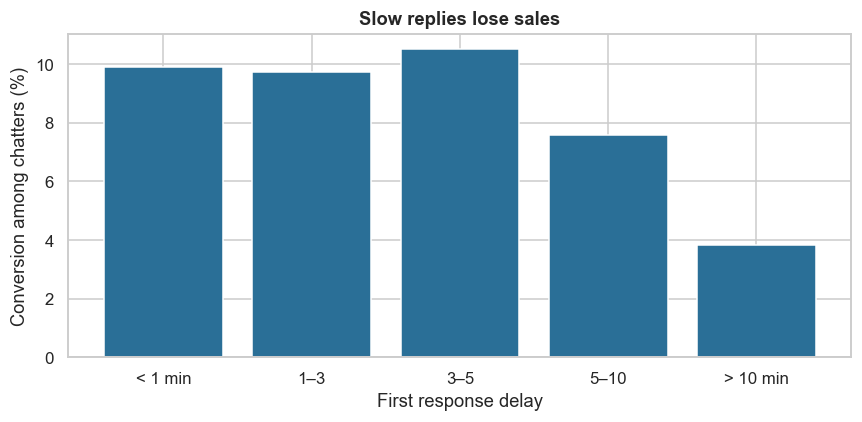

In [12]:
ch = df[(df.chatted == 1) & (df.delay_missing == 0)].copy()
ch["delay_band"] = pd.cut(ch.first_response_min, [-0.01, 1, 3, 5, 10, 1000], labels=["< 1 min", "1–3", "3–5", "5–10", "> 10 min"])
db = ch.groupby("delay_band").purchased.agg(["mean", "size"])
md = smf.logit("purchased ~ np.minimum(first_response_min, 30) + " + " + ".join(COV) + " + C(traffic_source)", data=ch).fit(disp=0)
pre_b, post_b = ch[ch.week <= 4].first_response_min, ch[ch.week >= 5].first_response_min
mwu = stats.mannwhitneyu(pre_b, post_b)
print(f"Delay > 5 min: before bot (wk 1–4) {(pre_b > 5).mean():.1%} vs bot era (wk 5–8) {(post_b > 5).mean():.1%} (documented 35% → 7–8%); Mann–Whitney p = {mwu.pvalue:.2g}")
print(f"Bot share of chats: wk 1–4 {ch[ch.week <= 4].bot_handled.mean():.0%} → wk 5–8 {ch[ch.week >= 5].bot_handled.mean():.0%}")
DT = "np.minimum(first_response_min, 30)"                                       # look the term up by name: patsy lists categorical dummies first
print(f"Adjusted odds ratio per extra minute of delay = {np.exp(md.params[DT]):.3f} (CI {np.exp(md.conf_int().loc[DT, 0]):.3f}–{np.exp(md.conf_int().loc[DT, 1]):.3f}), p = {md.pvalues[DT]:.2g}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(db.index.astype(str), db["mean"] * 100, color="#2a6f97"); ax.set_xlabel("First response delay"); ax.set_ylabel("Conversion among chatters (%)"); ax.set_title("Slow replies lose sales")
plt.tight_layout(); plt.show()

**Takeaway:** the bot cut slow responses (first reply > 5 minutes) from **45.5% of chats (weeks 1–4) to 5.9% (weeks 5–8)** (documented 35% → 7–8%), with the bot's share of chats rising from **21% to 79%** (documented 20% → 75–80%). Within chats, each extra minute of first-response delay lowers the odds of buying by **5.6%** (OR **0.944**, CI 0.935–0.953; p ≈ 5e-33), adjusted for intent signals and source. The chart shows conversion falling steadily with delay. **Business meaning:** speed matters, and that is where the bot earns its keep. A chat answered in seconds keeps the sale; one answered after ten minutes loses a large share of buyers (the same lesson as Case 28).

### 7.7 Power: how big must an encouragement test be?

IV estimates are noisy because only the *compliers* carry information. The sample needed scales with 1 / (first stage)².

In [13]:
p0_ = itt[0]; rows = []
for fs_ in (0.05, 0.09, 0.15, 0.25):
    for eff in (0.005, 0.01, 0.02):
        d_itt = fs_ * eff; n = int(np.ceil(2 * (1.96 + 0.84) ** 2 * p0_ * (1 - p0_) / d_itt ** 2)); rows.append((f"{fs_:.0%}", f"{eff * 100:.1f} pp", n))
pd.DataFrame(rows, columns=["first stage (pop-up → extra chat share)", "true effect of chatting", "visitors per arm (80% power)"]).pivot(index="first stage (pop-up → extra chat share)", columns="true effect of chatting", values="visitors per arm (80% power)")

true effect of chatting,0.5 pp,1.0 pp,2.0 pp
first stage (pop-up → extra chat share),,,
15%,1170496,292624,73156
25%,421379,105345,26337
5%,10534464,2633616,658404
9%,3251378,812845,203212


**Observation:** IV estimates are noisy because only people who chat *because of the pop-up* carry information. To detect a **2 pp** effect of chatting with a **9 pp** first stage, you need about **200,000 visitors per arm**; a 1 pp effect needs about 810,000; a 0.5 pp effect over 3 million. A stronger pop-up (a first stage of 25 pp) cuts these needs 3×. **Business meaning:** this experiment (≈ 112,000 per arm) can pin down a 3 pp effect but not a 1 pp one. A stronger or better-timed pop-up would make future tests cheaper.

## 8. ML Section — brief

The bot itself (Dialogflow NLU) cannot be reproduced without chat transcripts. Its documented evaluation metrics are bot response share, response delay, chat sales share and agent productivity. What the data science *can* evaluate is shown above: whether faster bot replies change conversion (7.6), and whether chat itself causes sales (7.5). For the bot's language model, the Case 30 notebook covers intent-classification evaluation (resolution rate with CSAT).

## 9. Business Translation — what does "push everyone to chat" really earn?

The documented plan raised the chat share of motor sales from 8–9% to almost 50%. We project the extra policies from raising visitor chat share from 9.7% to 30% (a realistic push) under three effect sizes:
- **Naive:** uses the raw difference (as if the 2× were causal).
- **AIPW-adjusted:** uses the observational estimate.
- **Experimental LATE:** uses the causal estimate for marginal (persuadable) chatters.

Assumptions (D-26-07): 30 lakh motor visitors a month; average premium from the data; 15% commission.

In [14]:
VIS_M = 3e6; COMM = 0.15; prem = df.loc[df.purchased == 1, "premium_inr"].mean(); extra_share = 0.30 - df.chatted.mean()
eff = {"naive (raw difference)": (a.purchased.mean() - b.purchased.mean()), "AIPW (observational, adjusted)": adj.loc["aipw", "RD (pp)"] / 100, "experimental LATE": late}
proj = pd.DataFrame([(k, v * 100, extra_share * VIS_M * v, extra_share * VIS_M * v * prem / 1e7, extra_share * VIS_M * v * prem * COMM / 1e7) for k, v in eff.items()],
                    columns=["effect assumption", "effect per new chatter (pp)", "extra policies / month", "extra premium ₹ crore / month", "extra commission ₹ crore / month"]).set_index("effect assumption")
lo_l, hi_l = np.percentile(bw, 2.5), np.percentile(bw, 97.5)
print(f"Average premium ₹{prem:,.0f}; raising chat share by {extra_share * 100:.1f} pp of 30 lakh visitors = {extra_share * VIS_M:,.0f} more chatters/month")
print(f"Experimental range (LATE CI): {extra_share * VIS_M * lo_l:,.0f} to {extra_share * VIS_M * hi_l:,.0f} extra policies/month")
proj.round(2)

Average premium ₹11,005; raising chat share by 20.3 pp of 30 lakh visitors = 609,330 more chatters/month
Experimental range (LATE CI): 7,530 to 31,898 extra policies/month


,effect per new chatter (pp),extra policies / month,extra premium ₹ crore / month,extra commission ₹ crore / month
effect assumption,,,,
naive (raw difference),4.7600,"28,997.4600",31.9100,4.7900
"AIPW (observational, adjusted)",3.6200,"22,043.9500",24.2600,3.6400
experimental LATE,3.5000,"21,333.8300",23.4800,3.5200


**Takeaway (business reading):** for **30 lakh visitors a month** with chat use raised from 9.7% to 30% (≈ **609,000 more chatters**; average premium ₹11,005; commission 15%):

| Effect assumption | Effect per new chatter | Extra policies a month | Extra commission |
|---|---|---|---|
| Raw 2× (naive) | +4.76 pp | ≈ 29,000 | ≈ ₹4.8 crore |
| Observational (AIPW) | +3.62 pp | ≈ 22,000 | ≈ ₹3.6 crore |
| **Experimental LATE** | **+3.50 pp (CI +1.24 to +5.23)** | **≈ 21,000 (range 7,500–31,900)** | **≈ ₹3.5 crore (range ₹1.2–5.3 crore)** |

- **The truth in the simulation is lower still:** about +2 pp per new chatter, i.e. ≈ 12,000 extra policies and ≈ ₹2 crore.
- **Reading:** a business case built on the raw 2× overstates the sales benefit by roughly 1.5–2.4×. The bot's economics are stronger on **agent productivity** (the documented 1.5–2 → 7–8 sales per agent-day) than on conversion. Plan on the conservative end of the experimental range.

## 10. Recommendation and Decision

**Decision against the hypotheses:**
- **H1 ✅:** chatters convert 2.15× as often (raw).
- **H2:** adjusted ATT is still +3.6 pp (significant), but not robust to hidden bias (E-value 2.8; Γ = 1.75).
- **H3 ✅:** the pop-up raises chat use and purchases (ITT +0.32 pp, p = 0.0002); LATE +3.5 pp (CI +1.2 to +5.2).
- **H4 ✅:** longer first-response delay lowers conversion (OR 0.944 per minute).

**I recommend:**
1. **Keep scaling the bot.** Speed is a real sales lever (slow replies fell from 45% to 6%) and it multiplies agent productivity.
2. **Forecast sales from the experiment,** not the raw 2×: plan for roughly +2–3.5 pp per additional chatter, with a range of +1 to +5 pp.
3. **Run a bigger, sharper encouragement test:** ≈ 200,000 visitors per arm to detect 2 pp, with a **placebo pop-up arm** (e.g., an FAQ link) to check that the pop-up affects buying only through chat.
4. **Target chat invitations** at visitors who are *not* already highly motivated (the marginal buyers), since keen buyers would buy anyway.
5. **Track cost per policy, not just conversion:** the bot's main benefit is agent output.

**KPIs:** conversion by randomised arm; chat uptake; share of responses > 5 minutes; bot share of chats; policies per agent-day; cost per policy; adjusted vs experimental effect estimates side by side.

## 11. Risks, Limitations and Next Steps

- **Synthetic effects:** the true chat effect (+0.35 log-odds) and the share of unobserved intent were assumed. The *method* (encouragement design + IV) is what transfers.
- **LATE is for compliers:** the IV estimate applies to visitors who chat *because of* the pop-up, the right group for a push-to-chat decision but not for already-keen chatters.
- **Exclusion restriction:** if the pop-up itself reassures visitors (a direct effect), the IV estimate is biased upward. A placebo pop-up (e.g., an FAQ link) arm would test this.
- **Agent productivity is real but separate:** the bot's main value may be **cost** (agents doing 7–8 sales/day instead of 1.5–2), even if chat's conversion effect is modest. Evaluate it in cost per policy, not conversion.
- **Spill-overs:** pushing everyone into chat lengthens queues. The bot is what keeps delays (and lost sales, 7.6) down.

## 12. Appendix

| Quantity | Formula |
|---|---|
| ATT via IPW | E[Y∣T=1] − Σ_{T=0} w·Y / Σ w, w = e/(1 − e) |
| AIPW (ATT) | μ₀ = [Σ_{T=1} m̂₀(x) + Σ_{T=0} w(Y − m̂₀(x))] / n₁ |
| Rosenbaum Γ (binary pairs) | worst-case p = P(Bin(D, Γ/(1+Γ)) ≥ n₁₀) |
| E-value | RR + √(RR(RR − 1)) |
| ITT | P(Y=1 ∣ Z=1) − P(Y=1 ∣ Z=0) |
| Wald / LATE | ITT / [P(T=1 ∣ Z=1) − P(T=1 ∣ Z=0)] |
| 2SLS | stage 1: T ~ Z + X; stage 2: Y ~ T̂ + X |
| IV sample size | n per arm ≈ 2(z₀.₉₇₅ + z₀.₈)² p(1−p) / (first stage × effect)² |

| Term | Meaning |
|---|---|
| Self-selection | People choose the channel, so channel users differ from non-users |
| Propensity score | Probability of choosing the channel given observed traits |
| ATT | Average effect on those who actually used the channel |
| Encouragement design | Randomising an invitation rather than forcing the behaviour |
| Complier | Someone who uses the channel only when invited |
| LATE | Local average treatment effect: the effect for compliers |
| E-value | How strong hidden confounding must be to explain a result away |